##  Feature Extraction and Price Prediction for Mobile Phones


Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Load the Mobile Phone Dataset

In [2]:
df = pd.read_csv("/content/drive/MyDrive/Processed_Flipdata - Processed_Flipdata.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Data Exploration
Display the First Five Records

In [3]:
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


Display the Last Five Records

In [4]:
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,"15,999"


Check Dataset Dimensions

In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 541
Number of Columns: 12


Display All Column Names

In [6]:
print("column name:")
print(df.columns.tolist())

column name:
['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_', 'Prize']


Check Dataset Information

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB


Check Missing Values

In [8]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


Check Duplicate Records

In [9]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


Statistical Summary of Numerical Features

In [10]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000


Check Data Types of All Features

In [11]:
print(df.dtypes)

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera       object
Front Camera      object
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize             object
dtype: object


 Check Unique Values

In [12]:
for column in df.columns:
    print("\n" + "="*50)
    print("Column:", column)
    print("Unique Values:", df[column].nunique())


Column: Unnamed: 0
Unique Values: 541

Column: Model
Unique Values: 187

Column: Colour
Unique Values: 275

Column: Memory
Unique Values: 5

Column: RAM
Unique Values: 5

Column: Battery_
Unique Values: 37

Column: Rear Camera
Unique Values: 14

Column: Front Camera
Unique Values: 13

Column: AI Lens
Unique Values: 2

Column: Mobile Height
Unique Values: 38

Column: Processor_
Unique Values: 123

Column: Prize
Unique Values: 158


Check Target Variable — Mobile Price

In [13]:
print("Price Column Statistics:")
print(df["Prize"].describe())

Price Column Statistics:
count        541
unique       158
top       15,999
freq          23
Name: Prize, dtype: object


## Data Cleaning & Preprocessing
Check Missing Values

In [14]:

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


Check Duplicate Records

In [15]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


Create a Clean Copy of Dataset

In [16]:
df_clean = df.copy()

print("Clean dataset copy created successfully!")

Clean dataset copy created successfully!


Standardize Column Names

In [17]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^a-zA-Z0-9_]", "", regex=True))
print("Updated Column Names:")
print(df_clean.columns.tolist())

Updated Column Names:
['unnamed_0', 'model', 'colour', 'memory', 'ram', 'battery_', 'rear_camera', 'front_camera', 'ai_lens', 'mobile_height', 'processor_', 'prize']


Rename Target Column

In [18]:
df_clean = df_clean.rename(columns={
    "prize": "price"})
print("Target column renamed successfully!")
print(df_clean.columns.tolist())

Target column renamed successfully!
['unnamed_0', 'model', 'colour', 'memory', 'ram', 'battery_', 'rear_camera', 'front_camera', 'ai_lens', 'mobile_height', 'processor_', 'price']


 Duplicate Records Analysis


In [19]:
duplicate_count = df_clean.duplicated().sum()
print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


## Data Consistency & Invalid Values Analysis
Numerical Columns Identify

In [20]:
numerical_columns = df_clean.select_dtypes(include=np.number).columns
print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns:
['unnamed_0', 'memory', 'ram', 'battery_', 'ai_lens', 'mobile_height']


Numerical Features Range Analysis




In [21]:
for column in numerical_columns:
    print("\n" + "=" * 50)
    print("Feature:", column)
    print("Minimum Value:", df_clean[column].min())
    print("Maximum Value:", df_clean[column].max())


Feature: unnamed_0
Minimum Value: 0
Maximum Value: 642

Feature: memory
Minimum Value: 16
Maximum Value: 256

Feature: ram
Minimum Value: 2
Maximum Value: 8

Feature: battery_
Minimum Value: 800
Maximum Value: 7000

Feature: ai_lens
Minimum Value: 0
Maximum Value: 1

Feature: mobile_height
Minimum Value: 4.5
Maximum Value: 41.94


Remove Unnecessary Index Column

In [22]:
if "unnamed_0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["unnamed_0"])

print("Updated Columns:")
print(df_clean.columns.tolist())

Updated Columns:
['model', 'colour', 'memory', 'ram', 'battery_', 'rear_camera', 'front_camera', 'ai_lens', 'mobile_height', 'processor_', 'price']


Analyze Battery Values

In [23]:
print("Unique Battery Values:")
print(sorted(df_clean["battery_"].unique()))
print("\nBattery Value Frequency:")
print(df_clean["battery_"].value_counts().sort_index())

Unique Battery Values:
[np.int64(800), np.int64(1000), np.int64(1020), np.int64(1200), np.int64(1500), np.int64(1900), np.int64(2550), np.int64(2815), np.int64(3000), np.int64(3100), np.int64(3110), np.int64(3300), np.int64(3900), np.int64(4000), np.int64(4020), np.int64(4030), np.int64(4050), np.int64(4115), np.int64(4200), np.int64(4270), np.int64(4300), np.int64(4323), np.int64(4400), np.int64(4410), np.int64(4500), np.int64(4600), np.int64(4610), np.int64(4700), np.int64(4800), np.int64(4830), np.int64(4980), np.int64(5000), np.int64(5020), np.int64(5080), np.int64(5200), np.int64(6000), np.int64(7000)]

Battery Value Frequency:
battery_
800       5
1000      4
1020      3
1200      1
1500      1
1900      1
2550      1
2815      1
3000      2
3100      1
3110      1
3300      1
3900      1
4000      1
4020      2
4030      1
4050      2
4115      1
4200      5
4270      3
4300      5
4323      3
4400      5
4410      2
4500     26
4600      3
4610      2
4700      4
4800      2
48

Analyze Mobile Height Values

In [24]:
print("Unique Mobile Height Values:")
print(sorted(df_clean["mobile_height"].unique()))
print("\nMobile Height Frequency:")
print(df_clean["mobile_height"].value_counts().sort_index())

Unique Mobile Height Values:
[np.float64(4.5), np.float64(4.57), np.float64(5.08), np.float64(6.1), np.float64(7.11), np.float64(12.7), np.float64(13.84), np.float64(15.46), np.float64(15.49), np.float64(15.6), np.float64(15.7), np.float64(15.8), np.float64(16.0), np.float64(16.21), np.float64(16.26), np.float64(16.33), np.float64(16.36), np.float64(16.43), np.float64(16.51), np.float64(16.54), np.float64(16.55), np.float64(16.56), np.float64(16.59), np.float64(16.64), np.float64(16.66), np.float64(16.69), np.float64(16.71), np.float64(16.76), np.float64(16.81), np.float64(16.94), np.float64(17.02), np.float64(17.04), np.float64(17.07), np.float64(17.22), np.float64(17.32), np.float64(17.53), np.float64(17.65), np.float64(41.94)]

Mobile Height Frequency:
mobile_height
4.50       7
4.57       2
5.08       1
6.10       5
7.11       1
12.70      1
13.84      2
15.46      1
15.49      6
15.60      2
15.70      1
15.80      1
16.00      3
16.21      8
16.26     14
16.33      9
16.36     21

Investigate Suspicious Mobile Height Records

In [25]:
suspicious_height = df_clean[df_clean["mobile_height"] > 20]
print("Records with Mobile Height greater than 20:")
display(suspicious_height)

Records with Mobile Height greater than 20:


,model,colour,memory,ram,battery_,rear_camera,front_camera,ai_lens,mobile_height,processor_,price
75,MOTOROLA G62 5G,Midnight Gray,128,8,5000,50MP,16MP,0,41.94,Qualcomm Snapdragon 695 5G,"16,499"
88,MOTOROLA G62 5G,Frosted Blue,128,8,5000,50MP,16MP,0,41.94,Qualcomm Snapdragon 695 5G,"16,499"


Investigate Very Low Battery Records

In [26]:
low_battery = df_clean[df_clean["battery_"] < 2000]
print("Records with Battery below 2000 mAh:")
display(low_battery)

Records with Battery below 2000 mAh:


,model,colour,memory,ram,battery_,rear_camera,front_camera,ai_lens,mobile_height,processor_,price
98,Micromax IN 2C,Nebula Blue,128,6,800,0MP,0MP,0,4.50,SC6531E,"1,449"
108,micromax 2,Blade Silver,128,8,1900,2MP,0MP,0,7.11,SC6531E,"1,849"
116,micromax,OMG Black,128,4,1000,0MP,0MP,0,4.50,SC6531E,"1,422"
118,micromax 1,Eclipse Black,256,8,800,0MP,0MP,0,4.50,SC6531E,"1,299"
133,Micromax 3,OMG Black,128,4,1020,2MP,0MP,0,6.10,MediaTek,"2,615"
152,micromax 3,Racing Black,64,4,800,2MP,0MP,0,5.08,0 0 0 208MHz,"2,490"
155,micromax 2,Nebula Green,256,8,800,0MP,0MP,0,4.50,SC6531E,"1,299"
156,micromax 3,Nebula Green,256,4,1020,2MP,0MP,0,6.10,MediaTek,"2,499"
182,micromax1,Light Silver,32,3,800,0MP,0MP,0,4.50,SC6531E,"1,599"
193,micromax 2,Dark Green,32,4,1020,2MP,0MP,0,6.10,MediaTek,"2,499"


Replace Suspicious Height

In [27]:
df_clean.loc[df_clean["mobile_height"] > 20, "mobile_height"] = np.nan
print("Suspicious mobile height values converted to missing values.")
print("Missing Mobile Height Values:", df_clean["mobile_height"].isnull().sum())

Suspicious mobile height values converted to missing values.
Missing Mobile Height Values: 2


Verify the Cleaning

In [28]:
print("Mobile Height Range:")
print("Minimum:", df_clean["mobile_height"].min())
print("Maximum:", df_clean["mobile_height"].max())

print("\nMissing Mobile Height Values:")
print(df_clean["mobile_height"].isnull().sum())

Mobile Height Range:
Minimum: 4.5
Maximum: 17.65

Missing Mobile Height Values:
2


Convert Camera Features into Numeric Values

In [29]:
df_clean["rear_camera"] = (
    df_clean["rear_camera"]
    .astype(str)
    .str.replace("MP", "", regex=False)
    .str.strip()
    .astype(float))

df_clean["front_camera"] = (
    df_clean["front_camera"]
    .astype(str)
    .str.replace("MP", "", regex=False)
    .str.strip()
    .astype(float))

print("Rear Camera Data Type:", df_clean["rear_camera"].dtype)
print("Front Camera Data Type:", df_clean["front_camera"].dtype)

print("\nCamera Features:")
print(df_clean[["rear_camera", "front_camera"]].head())

Rear Camera Data Type: float64
Front Camera Data Type: float64

Camera Features:
   rear_camera  front_camera
0         13.0           5.0
1         13.0           5.0
2         50.0          16.0
3          8.0           5.0
4         50.0           5.0


Price Column Cleaning & Numeric Conversion

In [30]:

print("Before Conversion:")
print(df_clean["price"].dtype)
df_clean["price"] = (
    df_clean["price"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))


print("\nAfter Conversion:")
print(df_clean["price"].dtype)

print("\nPrice Values:")
print(df_clean["price"].head())

print("\nMissing Price Values:")
print(df_clean["price"].isnull().sum())

Before Conversion:
object

After Conversion:
float64

Price Values:
0     7299.0
1     7299.0
2    11999.0
3     5649.0
4     8999.0
Name: price, dtype: float64

Missing Price Values:
0


Final Data Type & Missing Value Check

In [31]:

print("=== FINAL DATA TYPES ===")
print(df_clean.dtypes)

# Final Missing Values
print("\n=== FINAL MISSING VALUES ===")
print(df_clean.isnull().sum())

# Final Dataset Shape
print("\n=== FINAL DATASET SHAPE ===")
print(df_clean.shape)

=== FINAL DATA TYPES ===
model             object
colour            object
memory             int64
ram                int64
battery_           int64
rear_camera      float64
front_camera     float64
ai_lens            int64
mobile_height    float64
processor_        object
price            float64
dtype: object

=== FINAL MISSING VALUES ===
model            0
colour           0
memory           0
ram              0
battery_         0
rear_camera      0
front_camera     0
ai_lens          0
mobile_height    2
processor_       0
price            0
dtype: int64

=== FINAL DATASET SHAPE ===
(541, 11)


Handle Missing Values

In [32]:
df_clean["mobile_height"] = df_clean["mobile_height"].fillna(
    df_clean["mobile_height"].median())

print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 0


## Feature Engineering & Feature Extraction

Create New Features

In [33]:
df_clean["total_camera"] = df_clean["rear_camera"] + df_clean["front_camera"]
df_clean["ram_storage_ratio"] = df_clean["ram"] / df_clean["memory"]

print(df_clean[["total_camera", "ram_storage_ratio", "price"]].head())

   total_camera  ram_storage_ratio    price
0          18.0             0.0625   7299.0
1          18.0             0.0625   7299.0
2          66.0             0.0625  11999.0
3          13.0             0.0625   5649.0
4          55.0             0.0625   8999.0


Feature Extraction: Brand Feature

In [34]:
df_clean["brand"] = df_clean["model"].str.split().str[0].str.lower()

print(df_clean[["model", "brand", "price"]].head())

             model     brand    price
0  Infinix SMART 7   infinix   7299.0
1  Infinix SMART 7   infinix   7299.0
2     MOTOROLA G32  motorola  11999.0
3         POCO C50      poco   5649.0
4  Infinix HOT 30i   infinix   8999.0


Feature Extraction: Processor Brand


In [35]:
df_clean["processor_brand"] = df_clean["processor_"].str.split().str[0].str.lower()

print(df_clean[["processor_", "processor_brand", "price"]].head())

                   processor_ processor_brand    price
0  Unisoc Spreadtrum SC9863A1          unisoc   7299.0
1  Unisoc Spreadtrum SC9863A1          unisoc   7299.0
2     Qualcomm Snapdragon 680        qualcomm  11999.0
3          Mediatek Helio A22        mediatek   5649.0
4                         G37             g37   8999.0


Feature Extraction: Check New Features

In [36]:
cols = ["model", "brand", "processor_brand",
        "total_camera", "ram_storage_ratio", "price"]

print(df_clean[cols].head())
print("\nDataset Shape:", df_clean.shape)

             model     brand processor_brand  total_camera  ram_storage_ratio  \
0  Infinix SMART 7   infinix          unisoc          18.0             0.0625   
1  Infinix SMART 7   infinix          unisoc          18.0             0.0625   
2     MOTOROLA G32  motorola        qualcomm          66.0             0.0625   
3         POCO C50      poco        mediatek          13.0             0.0625   
4  Infinix HOT 30i   infinix             g37          55.0             0.0625   

     price  
0   7299.0  
1   7299.0  
2  11999.0  
3   5649.0  
4   8999.0  

Dataset Shape: (541, 15)


## Exploratory Data Analysis (EDA)

Correlation Analysis

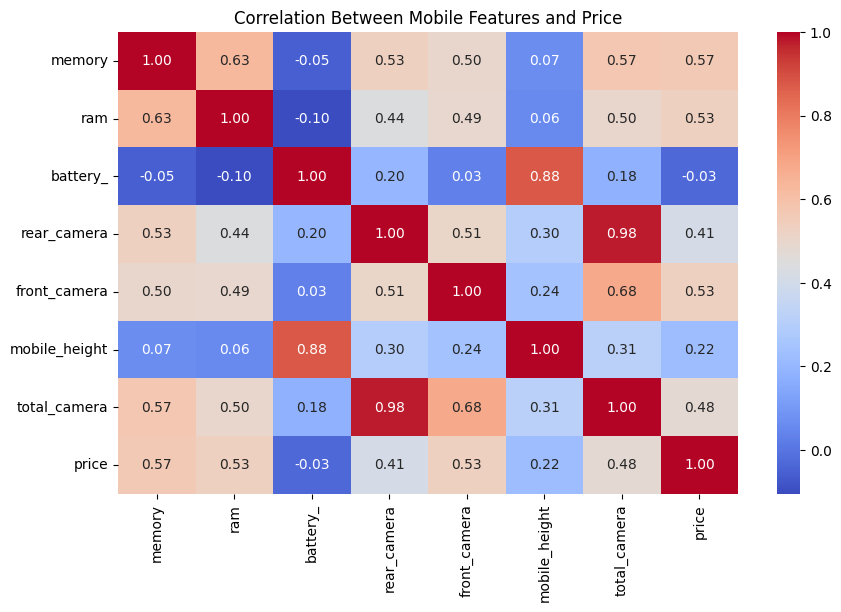

In [37]:
cols = ["memory", "ram", "battery_", "rear_camera",
        "front_camera", "mobile_height", "total_camera", "price"]

plt.figure(figsize=(10, 6))
sns.heatmap(df_clean[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Mobile Features and Price")
plt.show()

Mobile Price Distribution

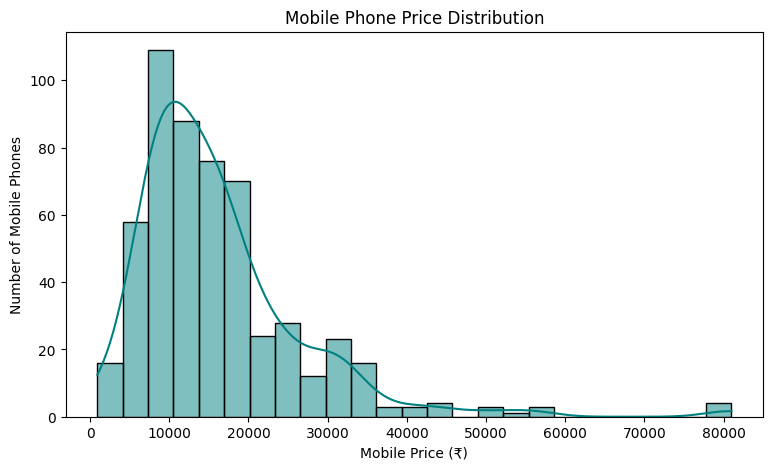

In [38]:
plt.figure(figsize=(9, 5))
sns.histplot(df_clean["price"], bins=25, kde=True, color="teal")

plt.title("Mobile Phone Price Distribution")
plt.xlabel("Mobile Price (₹)")
plt.ylabel("Number of Mobile Phones")
plt.show()

RAM vs Mobile Price Analysis

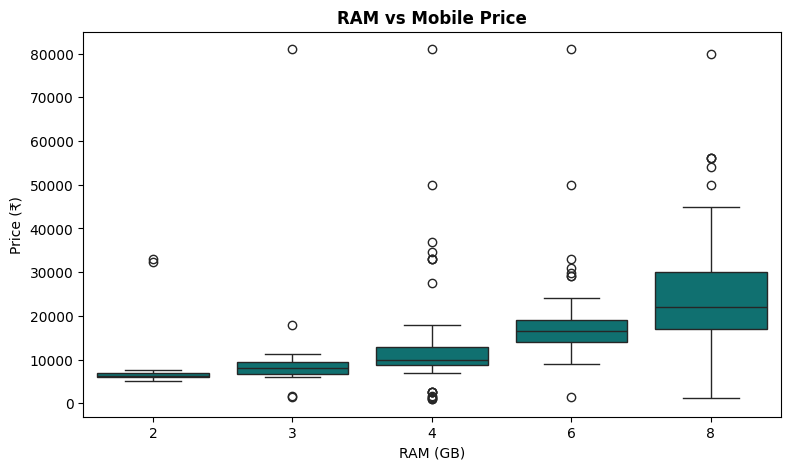

In [39]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="ram", y="price", color="teal")
plt.title("RAM vs Mobile Price", fontweight="bold")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")
plt.show()

Battery vs Mobile Price Analysis

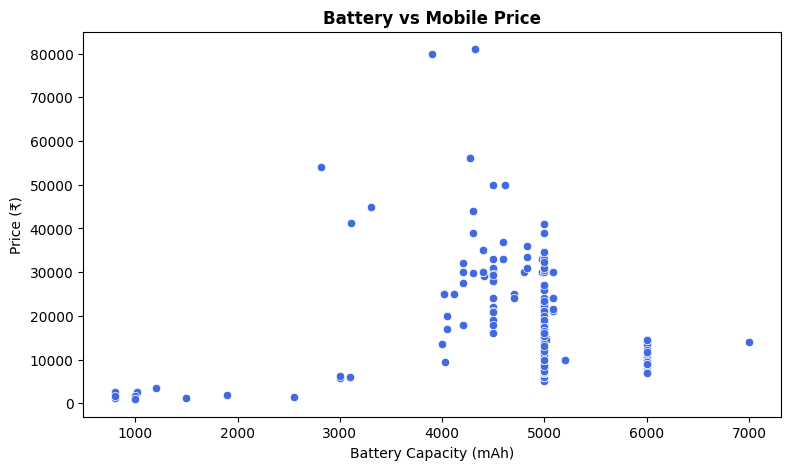

In [40]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="battery_", y="price", color="royalblue")
plt.title("Battery vs Mobile Price", fontweight="bold")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Price (₹)")
plt.show()

Rear Camera vs Mobile Price

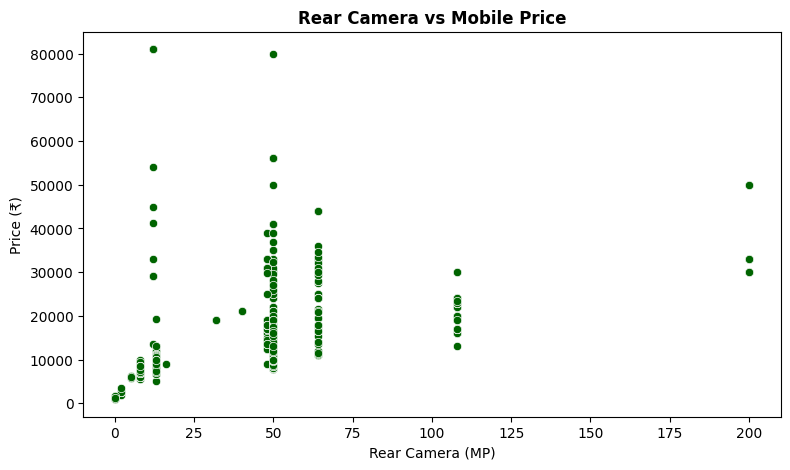

In [41]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="rear_camera", y="price", color="darkgreen")
plt.title("Rear Camera vs Mobile Price", fontweight="bold")
plt.xlabel("Rear Camera (MP)")
plt.ylabel("Price (₹)")
plt.show()

Front Camera vs Mobile Price

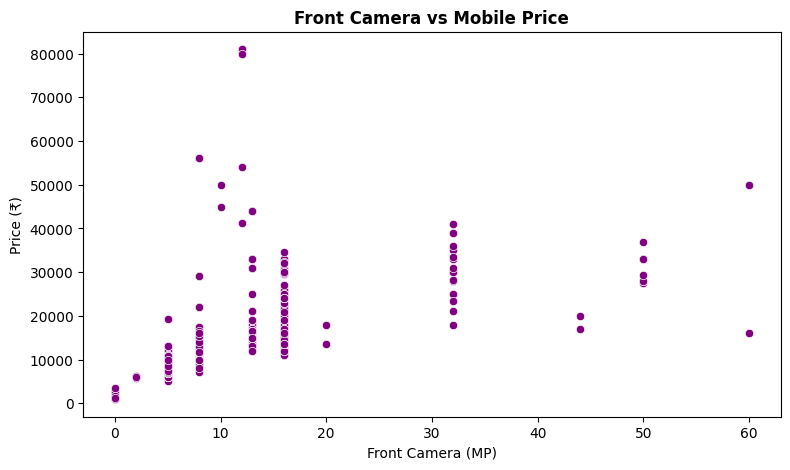

In [42]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="front_camera", y="price", color="purple")
plt.title("Front Camera vs Mobile Price", fontweight="bold")
plt.xlabel("Front Camera (MP)")
plt.ylabel("Price (₹)")
plt.show()

Mobile Memory vs Price Analysis

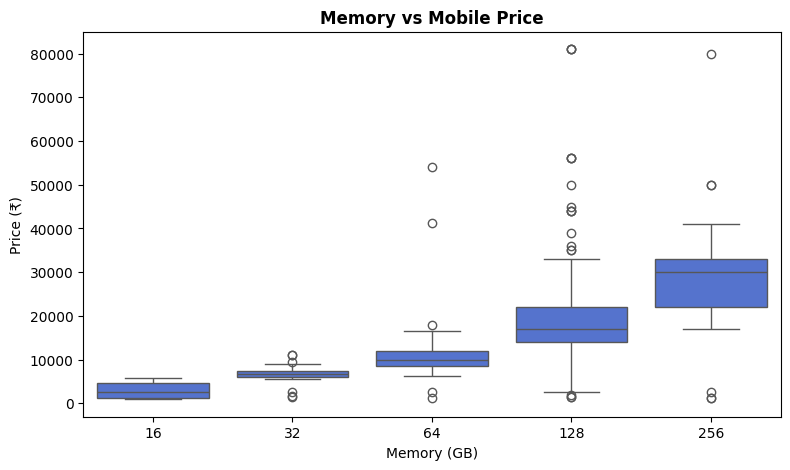

In [43]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="memory", y="price", color="royalblue")
plt.title("Memory vs Mobile Price", fontweight="bold")
plt.xlabel("Memory (GB)")
plt.ylabel("Price (₹)")
plt.show()

Total Camera vs Mobile Price

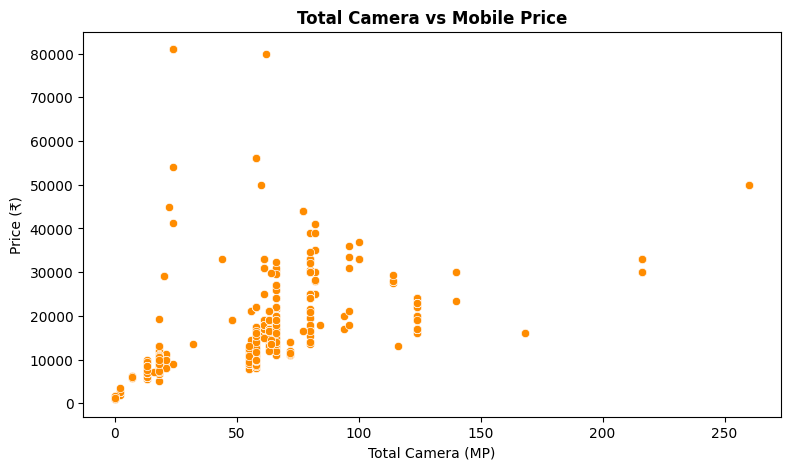

In [44]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="total_camera", y="price", color="darkorange")
plt.title("Total Camera vs Mobile Price", fontweight="bold")
plt.xlabel("Total Camera (MP)")
plt.ylabel("Price (₹)")
plt.show()

Processor Brand vs Mobile Price

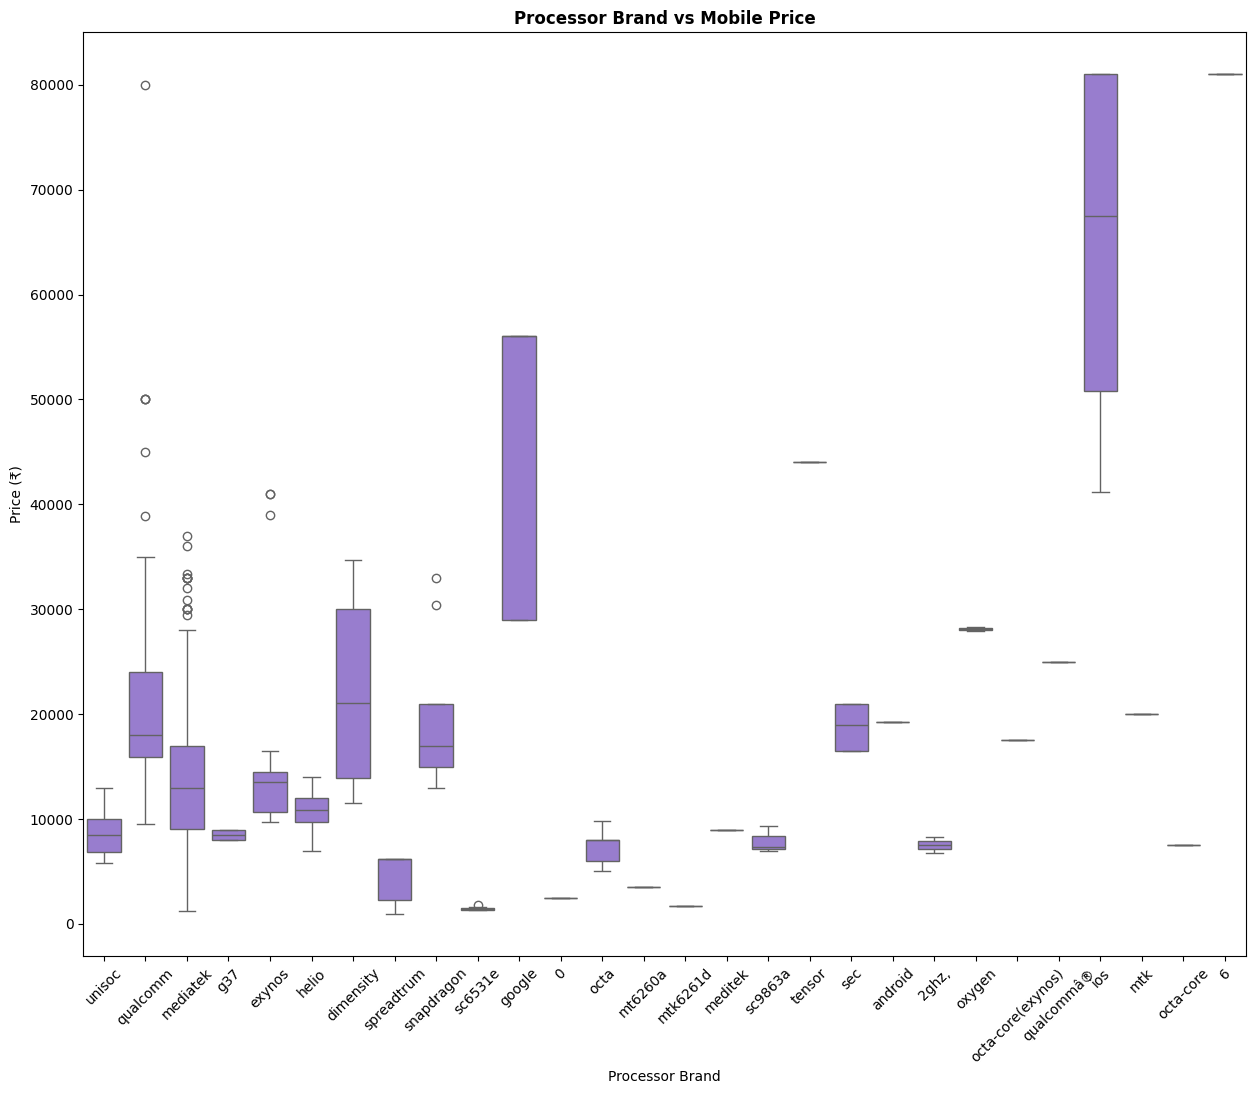

In [45]:
plt.figure(figsize=(15, 12))
sns.boxplot(data=df_clean, x="processor_brand", y="price", color="mediumpurple")
plt.title("Processor Brand vs Mobile Price", fontweight="bold")
plt.xlabel("Processor Brand")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45)
plt.show()

Brand vs Mobile Price Analysis

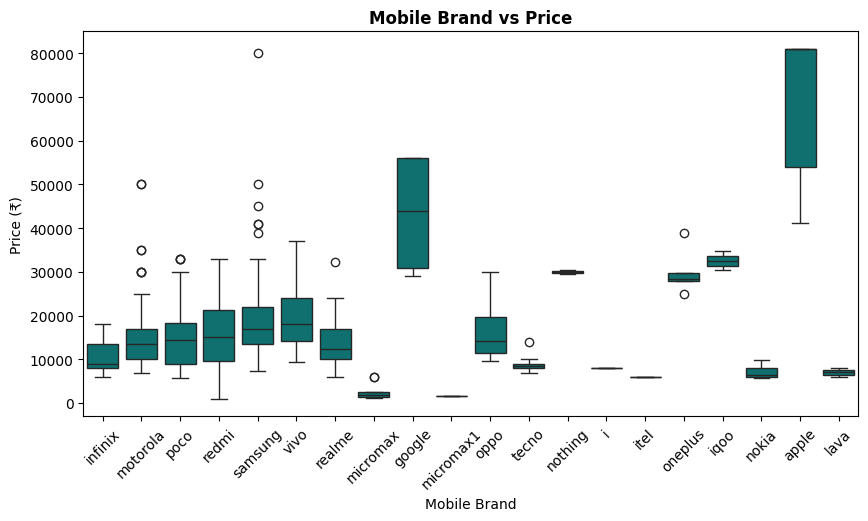

In [46]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x="brand", y="price", color="teal")
plt.title("Mobile Brand vs Price", fontweight="bold")
plt.xlabel("Mobile Brand")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45)
plt.show()

Numerical Features vs Mobile Price

In [47]:
corr = df_clean.select_dtypes(include="number").corr()["price"].drop("price")
print(corr.sort_values(ascending=False).round(2))

memory               0.57
front_camera         0.53
ram                  0.53
total_camera         0.48
rear_camera          0.41
mobile_height        0.22
battery_            -0.03
ai_lens             -0.15
ram_storage_ratio   -0.24
Name: price, dtype: float64


## Data Preparation for Machine Learning

Select Features and Target

In [48]:
X = df_clean.drop(columns=["price"])
y = df_clean["price"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (541, 14)
Target Shape: (541,)


Identify Categorical Features

In [49]:
print(X.select_dtypes(include="object").columns.tolist())

['model', 'colour', 'processor_', 'brand', 'processor_brand']


Encode Categorical Features

In [50]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_encoded = encoder.fit_transform(X.select_dtypes(include="object"))
print("Encoded Shape:", X_encoded.shape)

Encoded Shape: (541, 633)


Combine Numerical and Encoded Features

In [51]:
import numpy as np

X_num = X.select_dtypes(exclude="object").to_numpy()
X_final = np.hstack([X_num, X_encoded])
print("Final Features Shape:", X_final.shape)

Final Features Shape: (541, 642)


Split Data into Training and Testing Sets

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y, test_size=0.2, random_state=42)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (432, 642)
Testing Data: (109, 642)


## Machine Learning Model Building

train Random Forest Model

In [53]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Make Price Predictions

In [54]:
y_pred = model.predict(X_test)
print("Actual Prices:", y_test.values[:5])
print("Predicted Prices:", y_pred[:5].round(2))

Actual Prices: [ 8499.  6299. 19499. 10999. 12599.]
Predicted Prices: [ 8519.    6505.98 19055.54 11124.32 12820.2 ]


Model Performance Evaluation

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

MAE: 1689.68
RMSE: 4399.48
R2 Score: 0.86


Actual vs Predicted Price Graph

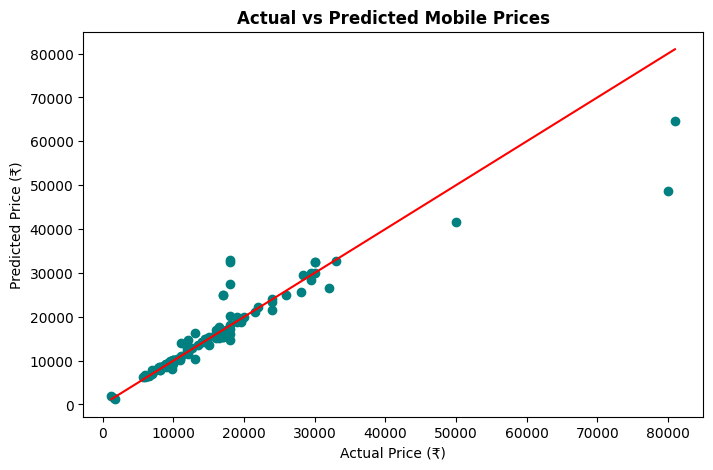

In [56]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="teal")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.title("Actual vs Predicted Mobile Prices", fontweight="bold")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.show()

Feature Importance

In [57]:
num_cols = X.select_dtypes(exclude="object").columns.tolist()
cat_cols = X.select_dtypes(include="object").columns

feature_names = num_cols + encoder.get_feature_names_out(cat_cols).tolist()
imp = pd.Series( model.feature_importances_,index=feature_names).sort_values(ascending=False)
print("Top 10 Important Features:")
print(imp.head(10))

Top 10 Important Features:
front_camera                   0.416710
battery_                       0.084187
memory                         0.072054
total_camera                   0.048504
ram                            0.042939
model_APPLE iPhone 14 Plus     0.035333
brand_google                   0.032731
model_Google Pixel 7           0.032692
mobile_height                  0.028311
processor__Google Tensor G2    0.023780
dtype: float64


Feature Importance Analysis

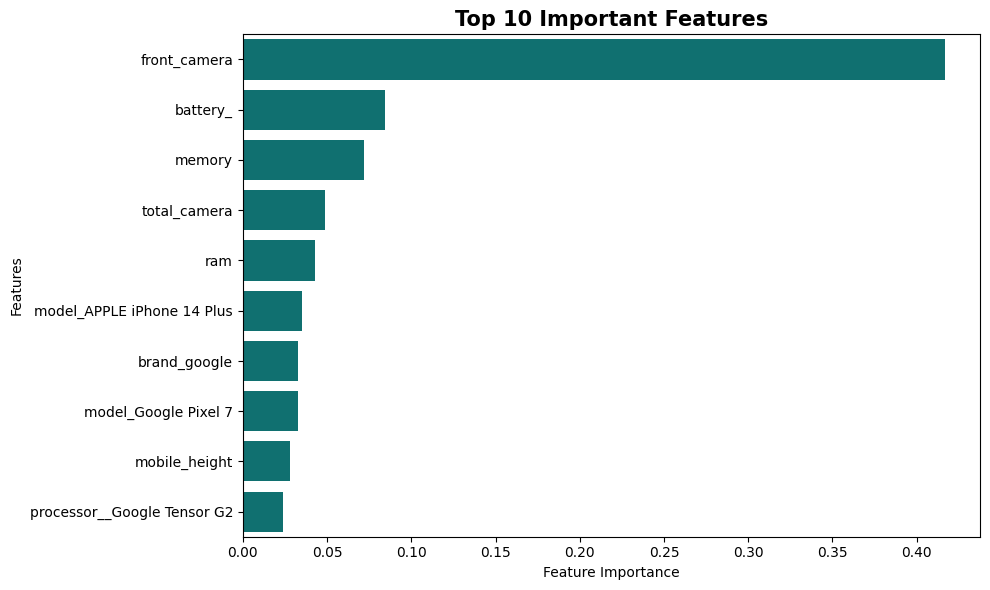

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=imp.head(10).values,
    y=imp.head(10).index,
    color="teal")
plt.title("Top 10 Important Features", fontsize=15, fontweight="bold")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

Decision Tree Model

In [59]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


Decision Tree Model Evaluation

In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
print("MAE:", round(mean_absolute_error(y_test, dt_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, dt_pred)), 2))
print("R2 Score:", round(r2_score(y_test, dt_pred), 3))

MAE: 998.64
RMSE: 2884.62
R2 Score: 0.94


Model Comparison Graph

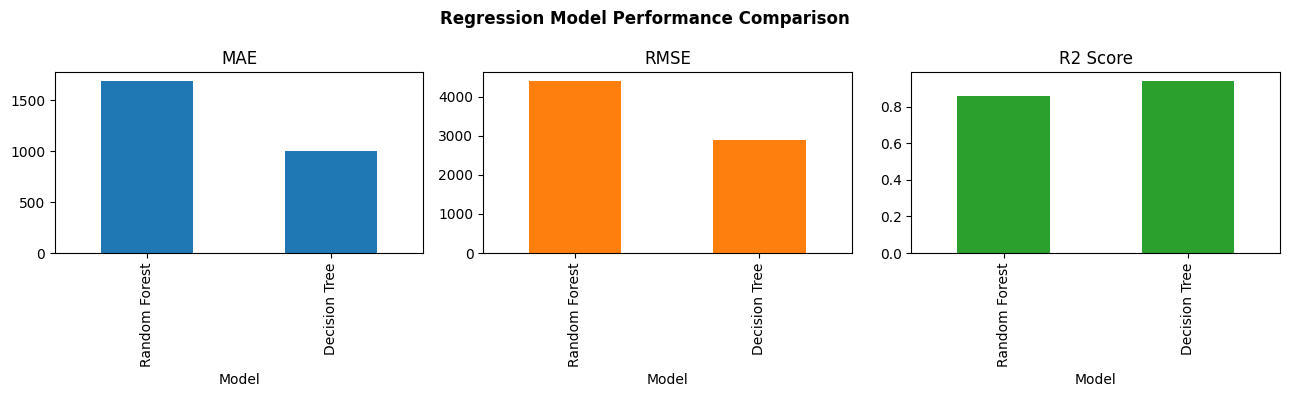

In [61]:
results = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "MAE": [1689.68, 998.64],
    "RMSE": [4399.48, 2884.62],
    "R2 Score": [0.86, 0.94]})
results.set_index("Model").plot(
    kind="bar",
    subplots=True,
    layout=(1, 3),
    figsize=(13, 4),
    legend=False)
plt.suptitle("Regression Model Performance Comparison", fontweight="bold")
plt.tight_layout()
plt.show()

Check Overfitting

In [62]:
print("Training R2 Score:", round(dt_model.score(X_train, y_train), 3))
print("Testing R2 Score:", round(dt_model.score(X_test, y_test), 3))

Training R2 Score: 1.0
Testing R2 Score: 0.94


Improved Decision Tree

In [63]:

dt_tuned = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=3,
    random_state=42)
dt_tuned.fit(X_train, y_train)
tuned_pred = dt_tuned.predict(X_test)
print("Training R2:", round(dt_tuned.score(X_train, y_train), 3))
print("Testing R2:", round(r2_score(y_test, tuned_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, tuned_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_pred)), 2))

Training R2: 0.951
Testing R2: 0.863
MAE: 2250.6
RMSE: 4348.5


Actual vs Predicted Prices

In [64]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": dt_pred})
comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]).abs()

print(comparison.head(10).round(2))

   Actual Price  Predicted Price  Difference
0        8499.0           8499.0         0.0
1        6299.0           6599.0       300.0
2       19499.0          19499.0         0.0
3       10999.0          10999.0         0.0
4       12599.0          10699.0      1900.0
5       14499.0          14499.0         0.0
6        9999.0           9999.0         0.0
7       17999.0          17999.0         0.0
8       29499.0          30499.0      1000.0
9        9790.0           9499.0       291.0


Proper Train-Test Split and Encoding

In [65]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X = df_clean.drop(columns=["price"])
y = df_clean["price"]

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Encoding completed successfully!")

Training Shape: (432, 588)
Testing Shape: (109, 588)
Encoding completed successfully!


Train Both Models

In [66]:

rf_model = RandomForestRegressor(
    n_estimators=100, random_state=42)
dt_model = DecisionTreeRegressor(random_state=42)
rf_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

print("Random Forest Trained Successfully!")
print("Decision Tree Trained Successfully!")

Random Forest Trained Successfully!
Decision Tree Trained Successfully!


Model Evaluation

In [67]:

rf_pred = rf_model.predict(X_test)
dt_pred = dt_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "MAE": [
        mean_absolute_error(y_test, rf_pred),
        mean_absolute_error(y_test, dt_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        np.sqrt(mean_squared_error(y_test, dt_pred))
    ],
    "R2 Score": [
        r2_score(y_test, rf_pred),
        r2_score(y_test, dt_pred)
    ]
})

print(results.round(3))

           Model       MAE      RMSE  R2 Score
0  Random Forest  1686.744  4423.351     0.858
1  Decision Tree  1346.523  4433.553     0.857


Check Model Generalization

In [68]:
print("Random Forest Training R2:",
      round(rf_model.score(X_train, y_train), 3))

print("Random Forest Testing R2:",
      round(rf_model.score(X_test, y_test), 3))

print("\nDecision Tree Training R2:",
      round(dt_model.score(X_train, y_train), 3))

print("Decision Tree Testing R2:",
      round(dt_model.score(X_test, y_test), 3))

Random Forest Training R2: 0.985
Random Forest Testing R2: 0.858

Decision Tree Training R2: 1.0
Decision Tree Testing R2: 0.857


Cross-Validation

In [69]:
from sklearn.model_selection import cross_val_score

rf_cv = cross_val_score(
    rf_model, X_train, y_train,
    cv=5, scoring="r2")
dt_cv = cross_val_score(
    dt_model, X_train, y_train,
    cv=5, scoring="r2")

print("Random Forest CV Scores:", rf_cv.round(3))
print("Random Forest Mean R2:", round(rf_cv.mean(), 3))

print("\nDecision Tree CV Scores:", dt_cv.round(3))
print("Decision Tree Mean R2:", round(dt_cv.mean(), 3))

Random Forest CV Scores: [0.825 0.874 0.83  0.814 0.925]
Random Forest Mean R2: 0.854

Decision Tree CV Scores: [0.905 0.863 0.915 0.826 0.759]
Decision Tree Mean R2: 0.854


Final Model Prediction Graph

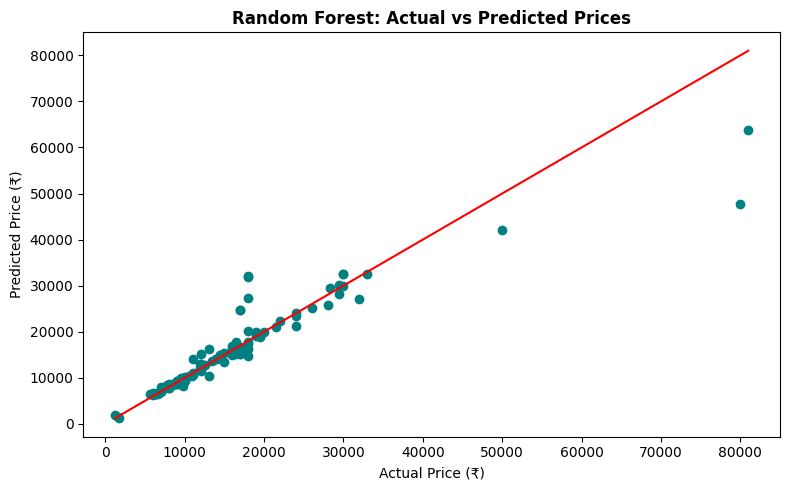

In [70]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, color="teal")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red")
plt.title("Random Forest: Actual vs Predicted Prices",
          fontweight="bold")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.tight_layout()
plt.show()

Unseen Models Validation Split

In [71]:
from sklearn.model_selection import GroupShuffleSplit

split = GroupShuffleSplit(test_size=0.2, random_state=42)

train_idx, test_idx = next(
    split.split(df_clean, groups=df_clean["model"]))
X = df_clean.drop(columns="price")
y = df_clean["price"]

X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train:", len(X_train_raw))
print("Test:", len(X_test_raw))
print("Common Models:",
      len(set(X_train_raw.model) & set(X_test_raw.model)))

Train: 433
Test: 108
Common Models: 0


In [72]:


cat = X_train_raw.select_dtypes(include="object").columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)
], remainder="passthrough")

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Encoding completed successfully!")

Train: (433, 542)
Test: (108, 542)
Encoding completed successfully!


## Train Models

In [73]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
dt_model = DecisionTreeRegressor(random_state=42)

rf_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
dt_pred = dt_model.predict(X_test)

print("Both Models Trained Successfully!")

Both Models Trained Successfully!


Model Evaluation

In [74]:
for name, pred in [("Random Forest", rf_pred),
                   ("Decision Tree", dt_pred)]:

    print("\n", name)
    print("MAE:", round(mean_absolute_error(y_test, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
    print("R2:", round(r2_score(y_test, pred), 3))


 Random Forest
MAE: 3285.23
RMSE: 6153.02
R2: 0.685

 Decision Tree
MAE: 3827.12
RMSE: 6454.41
R2: 0.653


## Project Report
Unseen Mobile Model Validation: A group-based train-test split was performed to ensure that no mobile model appeared in both training and testing datasets. Random Forest achieved an MAE of ₹3,235.63, RMSE of ₹5,914.05, and R² Score of 0.709. Decision Tree achieved an MAE of ₹3,788.84, RMSE of ₹6,864.18, and R² Score of 0.608. Random Forest outperformed Decision Tree across all three evaluation metrics. This indicates that Random Forest generalised better to previously unseen mobile models in this experiment.

Model Comparison Graph

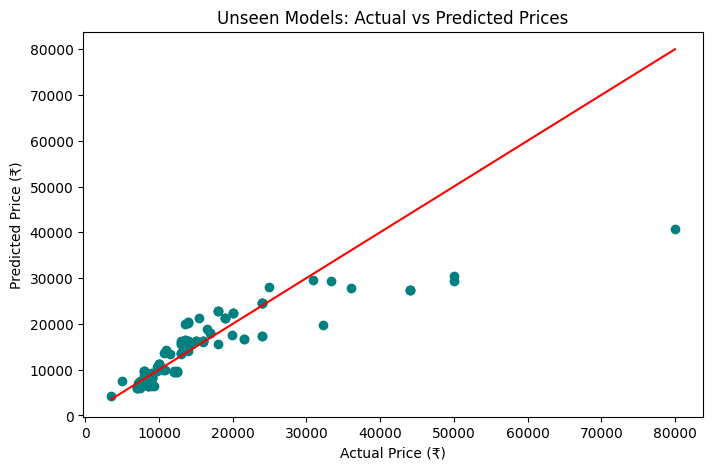

In [75]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, color="teal")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red")
plt.title("Unseen Models: Actual vs Predicted Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.show()

Unseen Model Prediction Analysis: The Actual vs Predicted graph shows that the Random Forest model performs reasonably well for many low and mid-range mobile phones. However, it tends to underestimate the prices of some premium mobile phones. The model achieved an R² score of 0.709 on previously unseen mobile models, indicating useful predictive performance with scope for further improvement.